In [1]:
import os
import json
import shutil
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from tensorflow.keras import Input, Model, Sequential
from tensorflow.keras.callbacks import LambdaCallback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import BatchNormalization, Dense, Dropout, Normalization, ReLU, Rescaling
from tensorflow.keras.models import load_model


In [2]:
if IN_COLAB:
    drive.mount('/content/drive')

    ZIP_PATH = "/content/drive/MyDrive/Proyecto IA/DatasetHidraulico.zip"
    EXTRACT_DIR = "/content/hydraulic_dataset"

    if not os.path.isfile(ZIP_PATH):
        raise FileNotFoundError(
            f"No encuentro el ZIP: {ZIP_PATH}\n"
            "Edita ZIP_PATH para que coincida con la ubicación del archivo en Drive."
        )

    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
else:
    posibles_rutas = [
        "condition+monitoring+of+hydraulic+systems",
        os.path.join(os.getcwd(), "condition+monitoring+of+hydraulic+systems"),
        "hydraulic_dataset"
    ]
    EXTRACT_DIR = next((r for r in posibles_rutas if os.path.isdir(r)), None)
    if EXTRACT_DIR is None:
        raise FileNotFoundError("No se encontró la carpeta con los archivos del dataset.")

file_paths = {}
for root, _, files_in_dir in os.walk(EXTRACT_DIR):
    for filename in files_in_dir:
        if filename.lower().endswith(".txt"):
            file_paths[filename.lower()] = os.path.join(root, filename)

# PS1 a PS6 miden presion en bar a 100hz
# EPS1 mide potencia electrica del motor en vatios a 100hz
# FS1 y FS2 miden caudal en litros por minuto a 10hz
# TS1 a TS4 miden temperatura del fluido en grados celsius a 1hz
# VS1 mide vibracion mecanica en milimetros por segundo a 1hz
# CE mide la eficiencia del enfriador en porcentaje a 1hz
# CP mide la potencia termica disipada en kilovatios a 1hz
# SE mide la eficiencia energetica global y se reserva como objetivo

sensor_names = [f"PS{i}" for i in range(1, 7)] + ["EPS1", "FS1", "FS2"] + \
               [f"TS{i}" for i in range(1, 5)] + ["VS1", "CE", "CP"]
required = sensor_names + ["profile", "se"]
missing = [name for name in required if f"{name.lower()}.txt" not in file_paths]
if missing:
    raise FileNotFoundError(f"Faltan archivos TXT: {missing}")

def read_txt(name):
    return pd.read_csv(file_paths[f"{name.lower()}.txt"],
                       sep="\t", header=None, dtype=np.float32, engine="python").to_numpy()

sensor_data = {name: read_txt(name) for name in sensor_names}
profile = read_txt("profile").astype(np.int64)
se_raw = read_txt("se")

assert profile.shape == (2205, 5), f"Dimensión inesperada de profile: {profile.shape}"
assert se_raw.shape == (2205, 60), f"Dimensión inesperada de SE: {se_raw.shape}"
assert all(x.shape[0] == 2205 for x in sensor_data.values()), "Las filas no están alineadas"
assert all(np.isfinite(x).all() for x in sensor_data.values()), "Hay valores no finitos en sensores"
assert np.isfinite(se_raw).all(), "Hay valores no finitos en SE"


In [3]:
def extract_sensor_features(row):
    row = np.asarray(row, dtype=np.float64)
    q25, q75 = np.percentile(row, [25, 75])
    stats = [
        row.mean(),
        row.std(),
        row.min(),
        row.max(),
        np.sqrt(np.mean(np.square(row))),
        row.max() - row.min(),
        q25,
        q75,
    ]
    segment_means = [segment.mean() for segment in np.array_split(row, 10)]
    return stats + segment_means

feature_names = []
for sensor in sensor_names:
    feature_names.extend([
        f"{sensor}_mean", f"{sensor}_std", f"{sensor}_min", f"{sensor}_max",
        f"{sensor}_rms", f"{sensor}_range", f"{sensor}_q25", f"{sensor}_q75"
    ])
    feature_names.extend([f"{sensor}_seg_{i}_mean" for i in range(1, 11)])

X = np.empty((2205, 288), dtype=np.float32)
for cycle in range(2205):
    row_features = []
    for sensor in sensor_names:
        row_features.extend(extract_sensor_features(sensor_data[sensor][cycle]))
    X[cycle] = row_features

assert X.shape == (2205, 288)
assert len(feature_names) == 288
assert np.isfinite(X).all()

cooler_map = {3: 0, 20: 1, 100: 2}
valve_map = {73: 0, 80: 1, 90: 2, 100: 3}
pump_map = {0: 0, 1: 1, 2: 2}

yc_original = profile[:, 0]
yv_original = profile[:, 1]
yb_original = profile[:, 2]

yc = np.array([cooler_map[int(v)] for v in yc_original], dtype=np.int64)
yv = np.array([valve_map[int(v)] for v in yv_original], dtype=np.int64)
yb = np.array([pump_map[int(v)] for v in yb_original], dtype=np.int64)
y_reg = se_raw.mean(axis=1).astype(np.float32).reshape(-1, 1)

# PREDICCIÓN ÚNICA DE FALLA GLOBAL (Target binario directo en el modelo):
# 1 = Falla crítica en subsistemas (Enfriador al 3%, Válvula al 73% o Bomba con fuga severa)
# 0 = Operación funcional (Sin falla crítica)
yf_original = (
    (yc_original == 3) | (yv_original == 73) | (yb_original == 2)
).astype(np.int64)
yf = yf_original.reshape(-1, 1).astype(np.float32)

print(f"Target 'falla' generado: {int(yf.sum())} ciclos con falla ({yf.mean()*100:.1f}%), {int((1-yf).sum())} sin falla")
assert not any(name.startswith("SE_") for name in feature_names)


Target 'falla' generado: 1220 ciclos con falla (55.3%), 985 sin falla


In [4]:
strata = np.array([
    f"{c}_{v}_{b}" for c, v, b in zip(yc_original, yv_original, yb_original)
])

if os.path.isfile("web/modelo/particiones.npz"):
    part = np.load("web/modelo/particiones.npz")
    idx_train, idx_val, idx_test = part["idx_train"], part["idx_val"], part["idx_test"]
else:
    indices = np.arange(len(X))
    idx_train, idx_temp = train_test_split(
        indices, test_size=0.30, stratify=strata, random_state=42
    )
    idx_val, idx_test = train_test_split(
        idx_temp, test_size=0.50, stratify=strata[idx_temp], random_state=42
    )

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
yc_train, yc_val, yc_test = yc[idx_train], yc[idx_val], yc[idx_test]
yv_train, yv_val, yv_test = yv[idx_train], yv[idx_val], yv[idx_test]
yb_train, yb_val, yb_test = yb[idx_train], yb[idx_val], yb[idx_test]
yr_train, yr_val, yr_test = y_reg[idx_train], y_reg[idx_val], y_reg[idx_test]
yf_train, yf_val, yf_test = yf[idx_train], yf[idx_val], yf[idx_test]

assert set(idx_train).isdisjoint(idx_val)
assert set(idx_train).isdisjoint(idx_test)
assert set(idx_val).isdisjoint(idx_test)


scaler_X ajustado con train (1543 ciclos) -> media global -0.000000 | desviacion 0.996522
scaler_y ajustado con train -> rango MinMax [0.0000, 1.0000]
=== ENTRADAS ANTES DEL ESCALADO (train, 6 features representativas) ===
                media       desv          min          max
PS1_mean   160.425003   4.639000   155.548996   180.867004
EPS1_max  2900.916016  49.500999  2813.399902  2995.199951
FS1_mean     6.210000   1.018000     2.019000     6.723000
TS1_mean    45.411999   7.977000    35.313999    57.840000
CE_mean     31.319000  11.572000    17.556000    47.896999
CP_mean      1.809000   0.279000     1.062000     2.840000
=== ENTRADAS DESPUES DEL ESCALADO (StandardScaler ajustado solo con train) ===
          media  desv    min    max
PS1_mean   -0.0   1.0 -1.051  4.406
EPS1_max   -0.0   1.0 -1.768  1.905
FS1_mean    0.0   1.0 -4.118  0.504
TS1_mean    0.0   1.0 -1.266  1.558
CE_mean     0.0   1.0 -1.189  1.433
CP_mean     0.0   1.0 -2.682  3.701
=== EFICIENCIA (salida de regresi

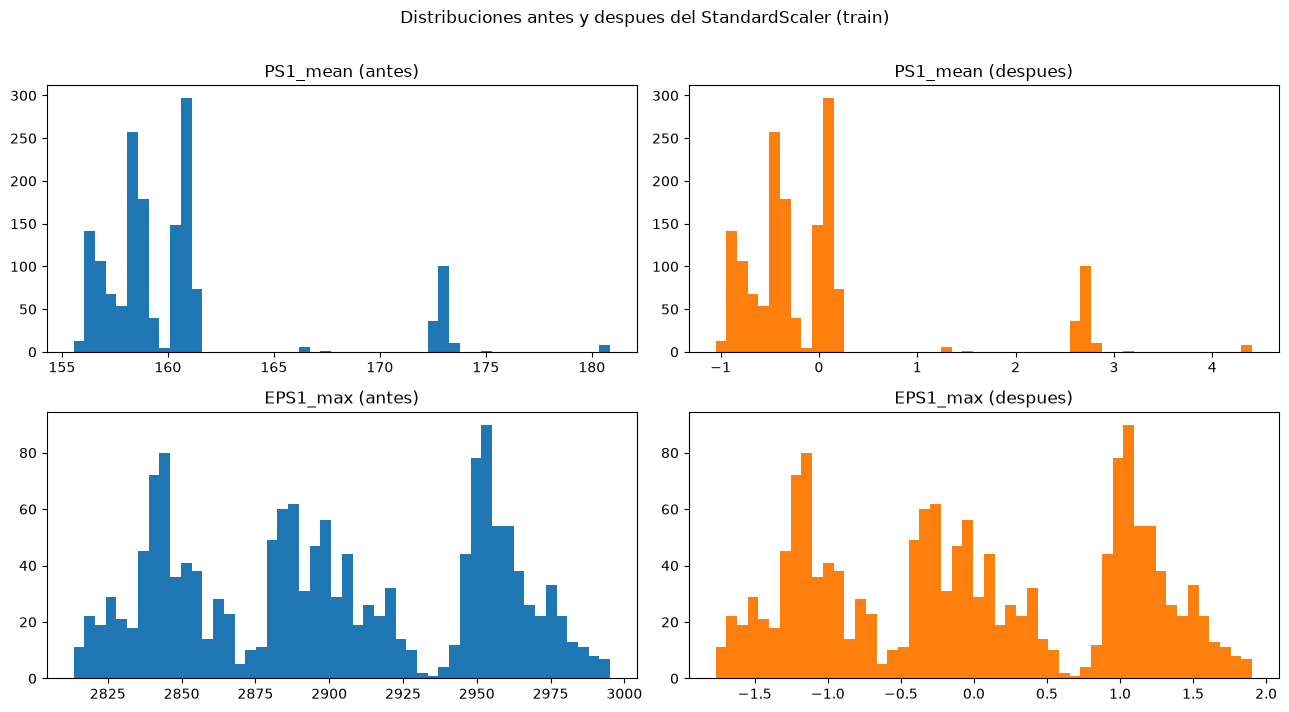

In [5]:
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler_X.transform(X_val).astype(np.float32)
X_test_scaled = scaler_X.transform(X_test).astype(np.float32)

scaler_y = MinMaxScaler()
yr_train_scaled = scaler_y.fit_transform(yr_train).astype(np.float32)
yr_val_scaled = scaler_y.transform(yr_val).astype(np.float32)
yr_test_scaled = scaler_y.transform(yr_test).astype(np.float32)

print(f"scaler_X ajustado con train ({X_train.shape[0]} ciclos) -> media global {X_train_scaled.mean():.6f} | desviacion {X_train_scaled.std():.6f}")
print(f"scaler_y ajustado con train -> rango MinMax [{yr_train_scaled.min():.4f}, {yr_train_scaled.max():.4f}]")

representativas = ["PS1_mean", "EPS1_max", "FS1_mean", "TS1_mean", "CE_mean", "CP_mean"]
posiciones = [feature_names.index(nombre) for nombre in representativas]

tabla_antes = pd.DataFrame({
    "media": X_train[:, posiciones].mean(axis=0),
    "desv": X_train[:, posiciones].std(axis=0),
    "min": X_train[:, posiciones].min(axis=0),
    "max": X_train[:, posiciones].max(axis=0),
}, index=representativas).round(3)
tabla_despues = pd.DataFrame({
    "media": X_train_scaled[:, posiciones].mean(axis=0),
    "desv": X_train_scaled[:, posiciones].std(axis=0),
    "min": X_train_scaled[:, posiciones].min(axis=0),
    "max": X_train_scaled[:, posiciones].max(axis=0),
}, index=representativas).round(3)

print("=== ENTRADAS ANTES DEL ESCALADO (train, 6 features representativas) ===")
print(tabla_antes.to_string())
print("=== ENTRADAS DESPUES DEL ESCALADO (StandardScaler ajustado solo con train) ===")
print(tabla_despues.to_string())

print("=== EFICIENCIA (salida de regresion) ===")
print(f"antes:  min {yr_train.min():.3f} | max {yr_train.max():.3f} | media {yr_train.mean():.3f}  [%]")
print(f"despues: min {yr_train_scaled.min():.4f} | max {yr_train_scaled.max():.4f} | media {yr_train_scaled.mean():.4f}  [escala 0-1]")

fig, ejes = plt.subplots(2, 2, figsize=(13, 7))
for fila, nombre in enumerate(["PS1_mean", "EPS1_max"]):
    posicion = feature_names.index(nombre)
    ejes[fila, 0].hist(X_train[:, posicion], bins=50, color="tab:blue")
    ejes[fila, 0].set_title(f"{nombre} (antes)")
    ejes[fila, 1].hist(X_train_scaled[:, posicion], bins=50, color="tab:orange")
    ejes[fila, 1].set_title(f"{nombre} (despues)")
plt.suptitle("Distribuciones antes y despues del StandardScaler (train)", y=1.01)
plt.tight_layout()
plt.show()


In [6]:
entrada = Input(shape=(288,), name="sensores")

base = Sequential([
    Dense(128),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),
    Dense(64),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),
], name="base_compartida")

representacion = base(entrada)

salida_cooler = Dense(3, activation="softmax", name="cooler")(representacion)
salida_valvula = Dense(4, activation="softmax", name="valvula")(representacion)
salida_bomba = Dense(3, activation="softmax", name="bomba")(representacion)
salida_eficiencia = Dense(1, activation="linear", name="eficiencia")(representacion)
salida_falla = Dense(1, activation="sigmoid", name="falla")(representacion)

model = Model(
    inputs=entrada,
    outputs=[
        salida_cooler,
        salida_valvula,
        salida_bomba,
        salida_eficiencia,
        salida_falla
    ]
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={
        "cooler": "sparse_categorical_crossentropy",
        "valvula": "sparse_categorical_crossentropy",
        "bomba": "sparse_categorical_crossentropy",
        "eficiencia": "mse",
        "falla": "binary_crossentropy",
    },
    loss_weights={
        "cooler": 1.0,
        "valvula": 2.0,
        "bomba": 1.0,
        "eficiencia": 1.0,
        "falla": 1.5,
    },
    metrics={
        "cooler": ["accuracy"],
        "valvula": ["accuracy"],
        "bomba": ["accuracy"],
        "eficiencia": ["mae"],
        "falla": ["accuracy"],
    },
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensores            │ (None, 288)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ base_compartida     │ (None, 64)        │     46,016 │ sensores[0][0]    │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cooler (Dense)      │ (None, 3)         │        195 │ base_compartida[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ valvula (Dense)     │ (None, 4)         │        260 │ base_compartida[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bomba (Dense)       │ (None, 3)         │        195 │ base_compartida[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ eficiencia (Dense)  │ (None, 1)         │         65 │ base_compartida[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ falla (Dense)       │ (None, 1)         │         65 │ base_compartida[… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 46,796 (182.80 KB)

 Trainable params: 46,412 (181.30 KB)

 Non-trainable params: 384 (1.50 KB)

In [7]:
callbacks = [
    EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
    ),
    LambdaCallback(on_epoch_end=lambda epoch, logs: logs.pop("learning_rate", None)),
]

history = model.fit(
    X_train_scaled,
    {
        "cooler": yc_train,
        "valvula": yv_train,
        "bomba": yb_train,
        "eficiencia": yr_train_scaled,
        "falla": yf_train,
    },
    validation_data=(
        X_val_scaled,
        {
            "cooler": yc_val,
            "valvula": yv_val,
            "bomba": yb_val,
            "eficiencia": yr_val_scaled,
            "falla": yf_val,
        },
    ),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/100


 1/49 ━━━━━━━━━━━━━━━━━━━━ 2:43 3s/step - bomba_accuracy: 0.3750 - bomba_loss: 1.4263 - cooler_accuracy: 0.1875 - cooler_loss: 1.6990 - eficiencia_loss: 1.0651 - eficiencia_mae: 0.8561 - falla_accuracy: 0.4062 - falla_loss: 0.8796 - loss: 9.8532 - valvula_accuracy: 0.1562 - valvula_loss: 2.1717

15/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - bomba_accuracy: 0.3104 - bomba_loss: 1.3645 - cooler_accuracy: 0.5542 - cooler_loss: 1.0187 - eficiencia_loss: 0.7915 - eficiencia_mae: 0.6766 - falla_accuracy: 0.5375 - falla_loss: 0.7424 - loss: 7.9904 - valvula_accuracy: 0.1979 - valvula_loss: 1.8510 

29/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - bomba_accuracy: 0.3427 - bomba_loss: 1.3002 - cooler_accuracy: 0.7177 - cooler_loss: 0.7523 - eficiencia_loss: 0.7525 - eficiencia_mae: 0.6527 - falla_accuracy: 0.6185 - falla_loss: 0.6529 - loss: 7.2166 - valvula_accuracy: 0.2769 - valvula_loss: 1.7161

45/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - bomba_accuracy: 0.3993 - bomba_loss: 1.2017 - cooler_accuracy: 0.7889 - cooler_loss: 0.6161 - eficiencia_loss: 0.6987 - eficiencia_mae: 0.6277 - falla_accuracy: 0.6604 - falla_loss: 0.5982 - loss: 6.6347 - valvula_accuracy: 0.3125 - valvula_loss: 1.6104

49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - bomba_accuracy: 0.4096 - bomba_loss: 1.1884 - cooler_accuracy: 0.7984 - cooler_loss: 0.5949 - eficiencia_loss: 0.6843 - eficiencia_mae: 0.6194 - falla_accuracy: 0.6708 - falla_loss: 0.5892 - loss: 6.5139 - valvula_accuracy: 0.3234 - valvula_loss: 1.5865

... (519 outputs left out)

42/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - bomba_accuracy: 0.9821 - bomba_loss: 0.0712 - cooler_accuracy: 0.9963 - cooler_loss: 0.0160 - eficiencia_loss: 0.0153 - eficiencia_mae: 0.0915 - falla_accuracy: 0.9940 - falla_loss: 0.0247 - loss: 0.2507 - valvula_accuracy: 0.9874 - valvula_loss: 0.0556

49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - bomba_accuracy: 0.9812 - bomba_loss: 0.0702 - cooler_accuracy: 0.9968 - cooler_loss: 0.0153 - eficiencia_loss: 0.0151 - eficiencia_mae: 0.0909 - falla_accuracy: 0.9935 - falla_loss: 0.0248 - loss: 0.2532 - valvula_accuracy: 0.9851 - valvula_loss: 0.0579 - val_bomba_accuracy: 0.9970 - val_bomba_loss: 0.0541 - val_cooler_accuracy: 0.9970 - val_cooler_loss: 0.0193 - val_eficiencia_loss: 0.0073 - val_eficiencia_mae: 0.0536 - val_falla_accuracy: 1.0000 - val_falla_loss: 0.0040 - val_loss: 0.1126 - val_valvula_accuracy: 0.9970 - val_valvula_loss: 0.0141


Epoch 88: early stopping


Restoring model weights from the end of the best epoch: 76.


In [8]:
results = model.evaluate(
    X_test_scaled,
    {
        "cooler": yc_test,
        "valvula": yv_test,
        "bomba": yb_test,
        "eficiencia": yr_test_scaled,
        "falla": yf_test,
    },
    return_dict=True,
    verbose=0,
)

pred_c, pred_v, pred_b, pred_r_scaled, pred_f = model.predict(X_test_scaled, verbose=0)
pred_c = pred_c.argmax(axis=1)
pred_v = pred_v.argmax(axis=1)
pred_b = pred_b.argmax(axis=1)
pred_f_cls = (pred_f.ravel() >= 0.5).astype(int)
pred_r = scaler_y.inverse_transform(pred_r_scaled)

print("=== COOLER ===")
print(classification_report(
    yc_test, pred_c, labels=[0, 1, 2],
    target_names=["3 %", "20 %", "100 %"], zero_division=0
))
print("=== VÁLVULA ===")
print(classification_report(
    yv_test, pred_v, labels=[0, 1, 2, 3],
    target_names=["73 %", "80 %", "90 %", "100 %"], zero_division=0
))
print("=== BOMBA ===")
print(classification_report(
    yb_test, pred_b, labels=[0, 1, 2],
    target_names=["0 fugas", "1 fuga", "2 fugas"], zero_division=0
))
print("=== PREDICCIÓN ÚNICA: FALLA GLOBAL (¿Va a fallar?) ===")
print(classification_report(
    yf_test.ravel(), pred_f_cls, labels=[0, 1],
    target_names=["No Falla (0)", "Falla (1)"], zero_division=0
))

mse_scaled = mean_squared_error(yr_test_scaled, pred_r_scaled)
mse_real = mean_squared_error(yr_test, pred_r)
mae_real = mean_absolute_error(yr_test, pred_r)
r2_real = r2_score(yr_test, pred_r)

print("=== REGRESIÓN: EFICIENCIA SE ===")
print(f"MSE normalizado: {mse_scaled:.6f}")
print(f"MSE en puntos porcentuales²: {mse_real:.4f}")
print(f"RMSE en puntos porcentuales: {np.sqrt(mse_real):.4f}")
print(f"MAE en puntos porcentuales: {mae_real:.4f}")
print(f"R²: {r2_real:.4f}")


=== COOLER ===
              precision    recall  f1-score   support

         3 %       1.00      1.00      1.00       110
        20 %       1.00      1.00      1.00       110
       100 %       1.00      1.00      1.00       111

    accuracy                           1.00       331
   macro avg       1.00      1.00      1.00       331
weighted avg       1.00      1.00      1.00       331

=== VÁLVULA ===
              precision    recall  f1-score   support

        73 %       0.98      1.00      0.99        54
        80 %       0.98      0.98      0.98        54
        90 %       1.00      0.98      0.99        54
       100 %       1.00      1.00      1.00       169

    accuracy                           0.99       331
   macro avg       0.99      0.99      0.99       331
weighted avg       0.99      0.99      0.99       331

=== BOMBA ===
              precision    recall  f1-score   support

     0 fugas       1.00      0.99      1.00       184
      1 fuga       0.99      1

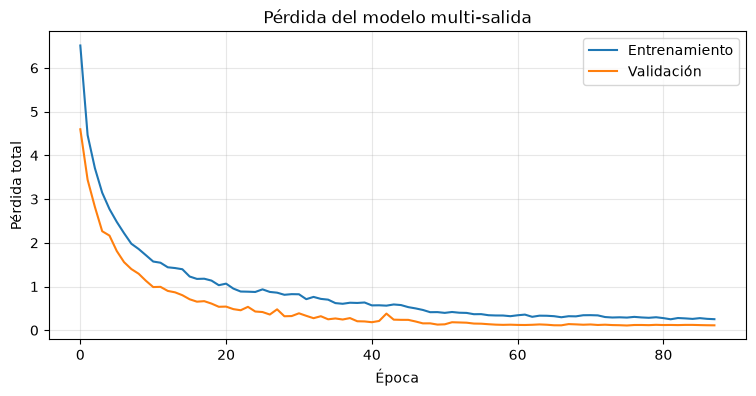

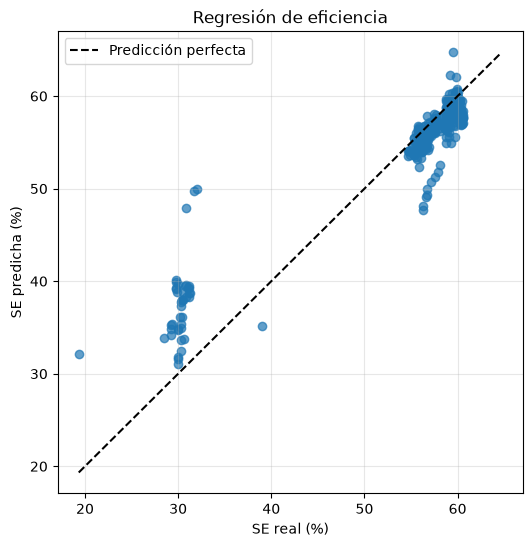

MSE baseline (porcentaje²): 92.7091
MSE red (porcentaje²):      12.3165
Reducción del MSE frente al baseline: 86.71%


In [9]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida total")
plt.title("Pérdida del modelo multi-salida")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(yr_test.ravel(), pred_r.ravel(), alpha=0.7)
lims = [
    min(float(yr_test.min()), float(pred_r.min())),
    max(float(yr_test.max()), float(pred_r.max())),
]
plt.plot(lims, lims, "k--", label="Predicción perfecta")
plt.xlabel("SE real (%)")
plt.ylabel("SE predicha (%)")
plt.title("Regresión de eficiencia")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(yr_train), 1)), yr_train.ravel())
baseline_pred = baseline.predict(np.zeros((len(yr_test), 1)))
baseline_mse = mean_squared_error(yr_test.ravel(), baseline_pred)

reduccion = 100 * (baseline_mse - mse_real) / baseline_mse if baseline_mse > 0 else 0
print(f"MSE baseline (porcentaje²): {baseline_mse:.4f}")
print(f"MSE red (porcentaje²):      {mse_real:.4f}")
print(f"Reducción del MSE frente al baseline: {reduccion:.2f}%")


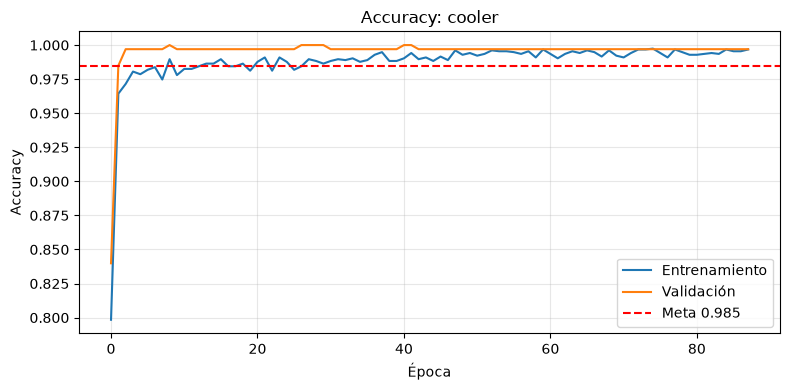

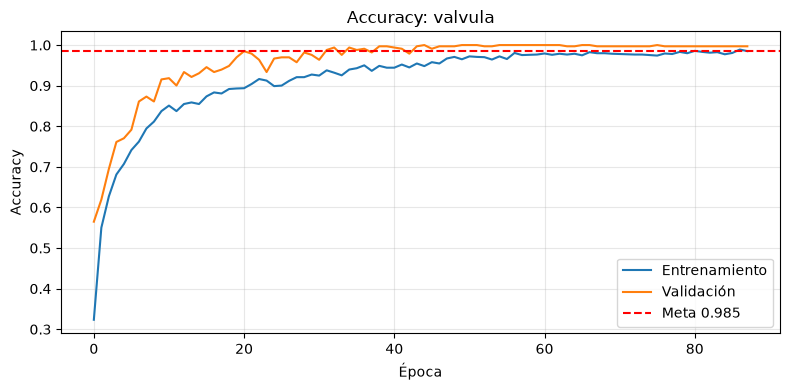

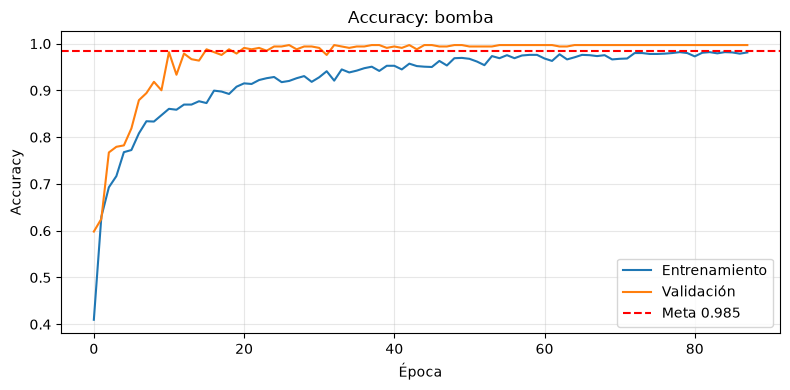

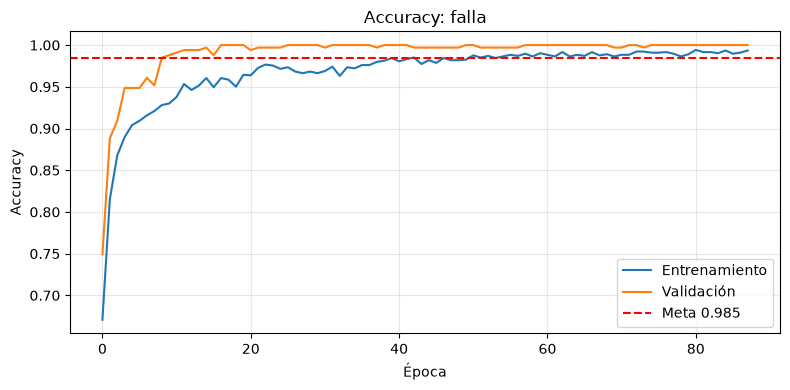

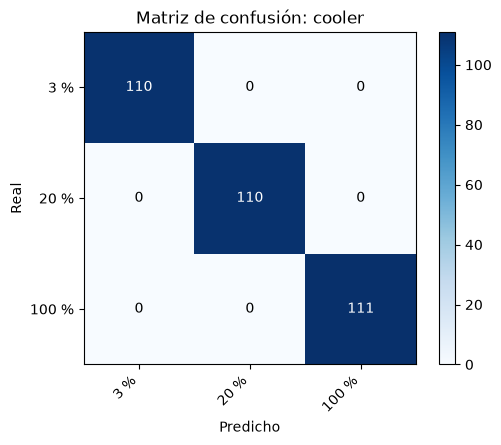

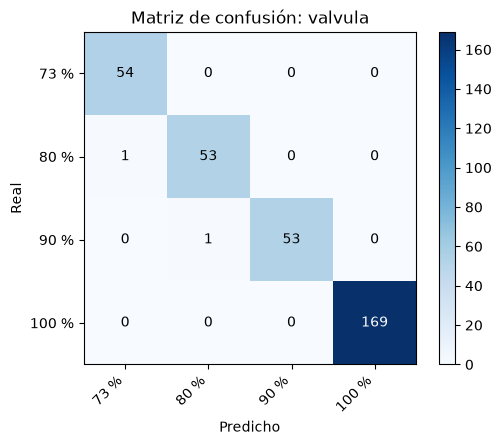

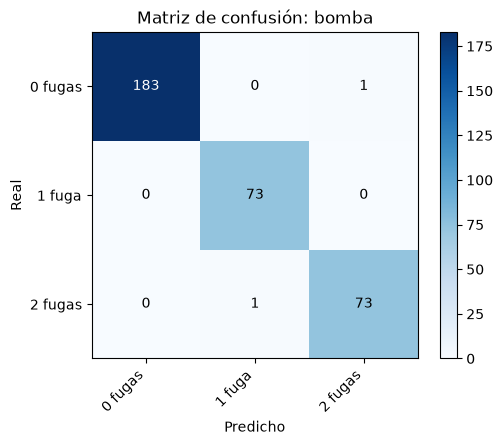

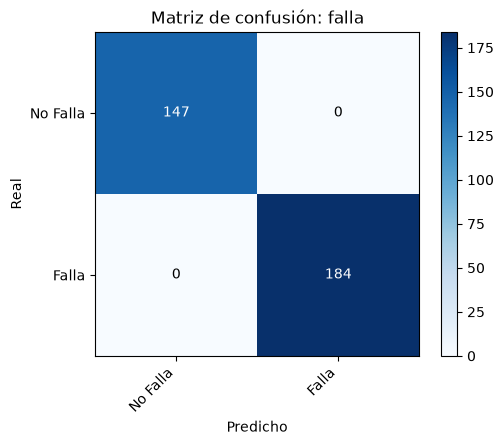

=== COOLER ===
Accuracy baseline (most_frequent): 0.3353
Accuracy red: 1.0000
=== VALVULA ===
Accuracy baseline (most_frequent): 0.5106
Accuracy red: 0.9940
=== BOMBA ===
Accuracy baseline (most_frequent): 0.5559
Accuracy red: 0.9940
=== FALLA ===
Accuracy baseline (most_frequent): 0.5559
Accuracy red: 1.0000


In [10]:
for nombre in ["cooler", "valvula", "bomba", "falla"]:
    plt.figure(figsize=(8, 4))
    plt.plot(history.history[f"{nombre}_accuracy"], label="Entrenamiento")
    plt.plot(history.history[f"val_{nombre}_accuracy"], label="Validación")
    plt.axhline(y=0.985, color="r", linestyle="--", label="Meta 0.985")
    plt.title(f"Accuracy: {nombre}")
    plt.xlabel("Época")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

matrices = [
    ("cooler", yc_test, pred_c, ["3 %", "20 %", "100 %"]),
    ("valvula", yv_test, pred_v, ["73 %", "80 %", "90 %", "100 %"]),
    ("bomba", yb_test, pred_b, ["0 fugas", "1 fuga", "2 fugas"]),
    ("falla", yf_test.ravel(), pred_f_cls, ["No Falla", "Falla"]),
]
for nombre, y_true, y_pred, etiquetas in matrices:
    plt.figure(figsize=(5.5, 4.5))
    cm = confusion_matrix(y_true, y_pred)
    plt.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black",
            )
    plt.xticks(range(len(etiquetas)), etiquetas, rotation=45, ha="right")
    plt.yticks(range(len(etiquetas)), etiquetas)
    plt.title(f"Matriz de confusión: {nombre}")
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.colorbar()
    plt.tight_layout()
    plt.show()

for nombre, y_train_tarea, y_test_tarea in [
    ("cooler", yc_train, yc_test),
    ("valvula", yv_train, yv_test),
    ("bomba", yb_train, yb_test),
    ("falla", yf_train.ravel(), yf_test.ravel()),
]:
    baseline_cls = DummyClassifier(strategy="most_frequent")
    baseline_cls.fit(np.zeros((len(y_train_tarea), 1)), y_train_tarea)
    pred_baseline = baseline_cls.predict(np.zeros((len(y_test_tarea), 1)))
    acc_baseline = float((pred_baseline == y_test_tarea).mean())
    print(f"=== {nombre.upper()} ===")
    print(f"Accuracy baseline (most_frequent): {acc_baseline:.4f}")
    print(f"Accuracy red: {results[f'{nombre}_accuracy']:.4f}")


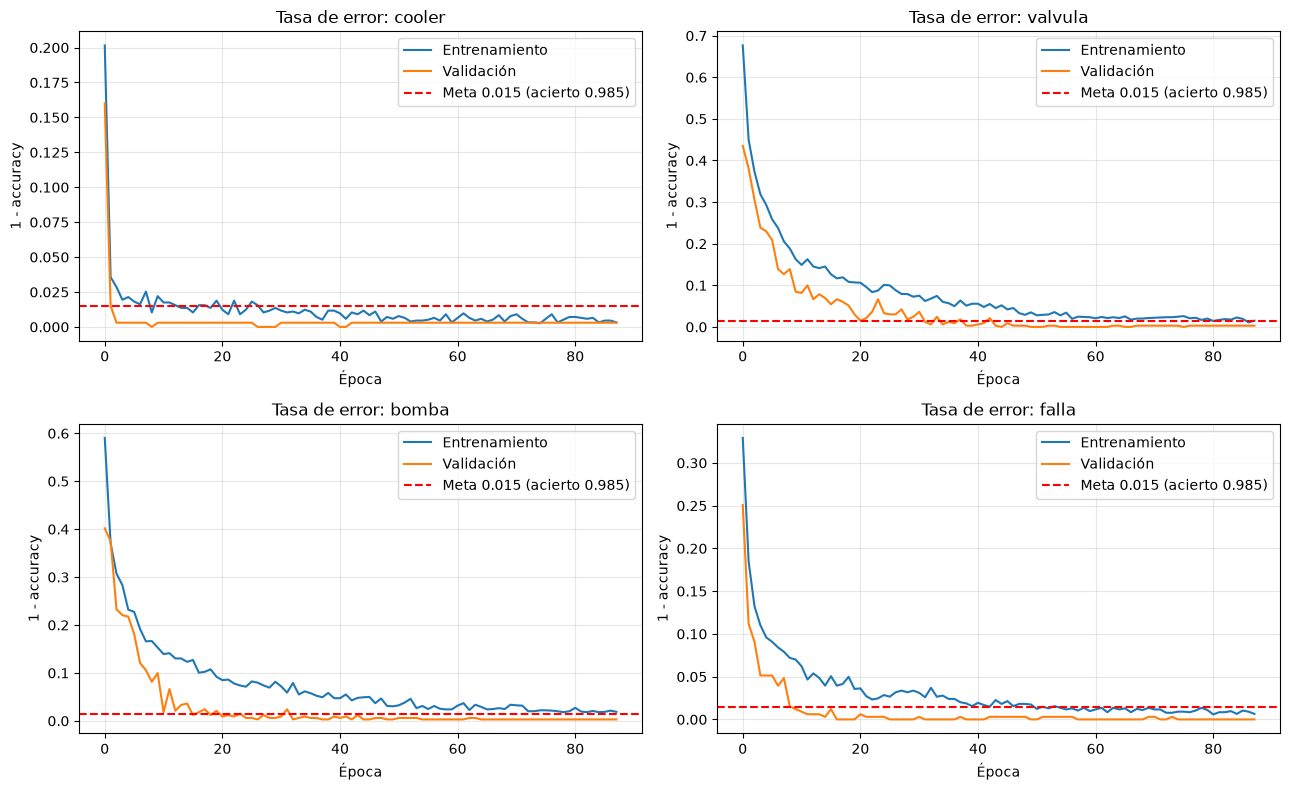

=== RESUMEN FRENTE A LAS METAS (test) ===
cooler: accuracy 1.0000 | errores 0/331 | meta > 0.985: CUMPLE
valvula: accuracy 0.9940 | errores 2/331 | meta > 0.985: CUMPLE
bomba: accuracy 0.9940 | errores 2/331 | meta > 0.985: CUMPLE
falla: accuracy 1.0000 | errores 0/331 | meta > 0.985: CUMPLE
eficiencia: MSE MinMax 0.006832 | meta < 0.03: CUMPLE


In [11]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8))
ejes = axs.ravel()

for ax, nombre in zip(ejes, ["cooler", "valvula", "bomba", "falla"]):
    error_train = 1 - np.array(history.history[f"{nombre}_accuracy"])
    error_val = 1 - np.array(history.history[f"val_{nombre}_accuracy"])
    ax.plot(error_train, label="Entrenamiento")
    ax.plot(error_val, label="Validación")
    ax.axhline(y=0.015, color="r", linestyle="--", label="Meta 0.015 (acierto 0.985)")
    ax.set_title(f"Tasa de error: {nombre}")
    ax.set_xlabel("Época")
    ax.set_ylabel("1 - accuracy")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("=== RESUMEN FRENTE A LAS METAS (test) ===")
for nombre, y_real, y_pred in [
    ("cooler", yc_test, pred_c),
    ("valvula", yv_test, pred_v),
    ("bomba", yb_test, pred_b),
    ("falla", yf_test.ravel(), pred_f_cls),
]:
    errores = int((y_real != y_pred).sum())
    acc = results[f"{nombre}_accuracy"]
    print(f"{nombre}: accuracy {acc:.4f} | errores {errores}/{len(y_real)} | meta > 0.985: {'CUMPLE' if acc > 0.985 else 'NO CUMPLE'}")
print(f"eficiencia: MSE MinMax {mse_scaled:.6f} | meta < 0.03: {'CUMPLE' if mse_scaled < 0.03 else 'NO CUMPLE'}")


In [12]:
entrada_cruda = Input(shape=(288,), name="sensores")
normalizacion = Normalization(
    mean=scaler_X.mean_.astype(np.float32),
    variance=np.square(scaler_X.scale_).astype(np.float32),
    name="normalizacion",
)
representacion_cruda = base(normalizacion(entrada_cruda))
salida_cooler_w = model.get_layer("cooler")(representacion_cruda)
salida_valvula_w = model.get_layer("valvula")(representacion_cruda)
salida_bomba_w = model.get_layer("bomba")(representacion_cruda)
salida_falla_w = model.get_layer("falla")(representacion_cruda)

capa_eficiencia_pre = Dense(1, name="eficiencia_pre")
salida_eficiencia_escala = capa_eficiencia_pre(representacion_cruda)
capa_eficiencia_pre.set_weights(model.get_layer("eficiencia").get_weights())
rango_eficiencia = float(scaler_y.data_max_[0] - scaler_y.data_min_[0])
minimo_eficiencia = float(scaler_y.data_min_[0])
salida_eficiencia = Rescaling(
    scale=rango_eficiencia, offset=minimo_eficiencia, name="eficiencia"
)(salida_eficiencia_escala)

wrapper = Model(
    inputs=entrada_cruda,
    outputs=[salida_cooler_w, salida_valvula_w, salida_bomba_w, salida_eficiencia, salida_falla_w],
)
wrapper.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={
        "cooler": "sparse_categorical_crossentropy",
        "valvula": "sparse_categorical_crossentropy",
        "bomba": "sparse_categorical_crossentropy",
        "eficiencia": "mse",
        "falla": "binary_crossentropy",
    },
    loss_weights={"cooler": 1.0, "valvula": 2.0, "bomba": 1.0, "eficiencia": 1.0, "falla": 1.5},
    metrics={
        "cooler": ["accuracy"],
        "valvula": ["accuracy"],
        "bomba": ["accuracy"],
        "eficiencia": ["mae"],
        "falla": ["accuracy"],
    },
)

assert wrapper.output_names == ["cooler", "valvula", "bomba", "eficiencia", "falla"]

wc, wv, wb, wp, wf = wrapper.predict(X_test, verbose=0)
pc_s, pv_s, pb_s, pr_s, pf_s = model.predict(X_test_scaled, verbose=0)
pr_pct_referencia = scaler_y.inverse_transform(pr_s)

prob_cooler = float(np.max(np.abs(pc_s - wc)))
prob_valvula = float(np.max(np.abs(pv_s - wv)))
prob_bomba = float(np.max(np.abs(pb_s - wb)))
prob_falla = float(np.max(np.abs(pf_s - wf)))
clases_coinciden = bool(
    np.array_equal(pc_s.argmax(axis=1), wc.argmax(axis=1))
    and np.array_equal(pv_s.argmax(axis=1), wv.argmax(axis=1))
    and np.array_equal(pb_s.argmax(axis=1), wb.argmax(axis=1))
    and np.array_equal((pf_s.ravel() >= 0.5), (wf.ravel() >= 0.5))
)
diferencia_eficiencia = float(np.max(np.abs(pr_pct_referencia - wp)))

resultados_wrapper = wrapper.evaluate(
    X_test,
    {
        "cooler": yc_test,
        "valvula": yv_test,
        "bomba": yb_test,
        "eficiencia": yr_test,
        "falla": yf_test,
    },
    return_dict=True,
    verbose=0,
)
accuracy_equivalente = bool(
    all(
        resultados_wrapper[f"{nombre}_accuracy"] == results[f"{nombre}_accuracy"]
        for nombre in ["cooler", "valvula", "bomba", "falla"]
    )
)
mse_wrapper = mean_squared_error(yr_test, wp)
mae_wrapper = mean_absolute_error(yr_test, wp)
r2_wrapper = r2_score(yr_test, wp)

ruta_roundtrip = "/content/modelo_wrapper_roundtrip.keras" if IN_COLAB else "modelo_wrapper_roundtrip.keras"
wrapper.save(ruta_roundtrip)
wrapper_cargado = load_model(ruta_roundtrip, compile=False)
rc, rv, rb, rp, rf = wrapper_cargado.predict(X_test, verbose=0)
roundtrip_equivalente = bool(
    np.allclose(wc, rc, atol=1e-6)
    and np.allclose(wv, rv, atol=1e-6)
    and np.allclose(wb, rb, atol=1e-6)
    and np.allclose(wp, rp, atol=1e-6)
    and np.allclose(wf, rf, atol=1e-6)
)
if os.path.exists(ruta_roundtrip):
    os.remove(ruta_roundtrip)

validacion_ok = bool(
    prob_cooler <= 1e-5
    and prob_valvula <= 1e-5
    and prob_bomba <= 1e-5
    and prob_falla <= 1e-5
    and clases_coinciden
    and diferencia_eficiencia <= 0.01
    and accuracy_equivalente
    and roundtrip_equivalente
)

print("=== VALIDACIÓN DEL WRAPPER ===")
print(f"Prob. máx dif cooler: {prob_cooler:.2e} (<= 1e-5)")
print(f"Prob. máx dif valvula: {prob_valvula:.2e} (<= 1e-5)")
print(f"Prob. máx dif bomba: {prob_bomba:.2e} (<= 1e-5)")
print(f"Prob. máx dif falla: {prob_falla:.2e} (<= 1e-5)")
print(f"Clases coinciden: {clases_coinciden}")
print(f"Dif. máx eficiencia: {diferencia_eficiencia:.6f} pp (<= 0.01)")
print(f"Accuracy equivalente: {accuracy_equivalente}")
print(f"Round-trip equivalente: {roundtrip_equivalente}")
print(f"MSE wrapper (pp²): {mse_wrapper:.4f} | MAE (pp): {mae_wrapper:.4f} | R²: {r2_wrapper:.4f}")
print(f"VALIDACION_OK: {validacion_ok}")


=== VALIDACIÓN DEL WRAPPER ===
Prob. máx dif cooler: 1.19e-07 (<= 1e-5)
Prob. máx dif valvula: 2.38e-07 (<= 1e-5)
Prob. máx dif bomba: 3.28e-07 (<= 1e-5)
Prob. máx dif falla: 2.98e-08 (<= 1e-5)
Clases coinciden: True
Dif. máx eficiencia: 0.000008 pp (<= 0.01)
Accuracy equivalente: True
Round-trip equivalente: True
MSE wrapper (pp²): 12.3165 | MAE (pp): 2.1776 | R²: 0.8665
VALIDACION_OK: True


In [13]:
inv_cooler = {v: k for k, v in cooler_map.items()}
inv_valvula = {v: k for k, v in valve_map.items()}
inv_bomba = {v: k for k, v in pump_map.items()}

rng = np.random.default_rng(42)
ciclos = rng.choice(idx_test, size=5, replace=False)

filas = []
for ciclo in ciclos:
    caracteristicas = []
    for sensor in sensor_names:
        caracteristicas.extend(extract_sensor_features(sensor_data[sensor][ciclo]))
    x_nuevo = np.array(caracteristicas, dtype=np.float32).reshape(1, 288)

    pc, pv, pb, pe, pf = wrapper.predict(x_nuevo, verbose=0)
    se_real = float(se_raw[ciclo].mean())
    se_pred = float(pe[0, 0])
    va_a_fallar_pred = bool(pf[0, 0] >= 0.5)
    falla_real = bool(yf[ciclo, 0] == 1)

    filas.append({
        "ciclo": int(ciclo),
        "falla real": "SÍ" if falla_real else "NO",
        "¿va a fallar? (pred)": f"{'SÍ' if va_a_fallar_pred else 'NO'} ({pf[0, 0]*100:.1f}%)",
        "cooler real": int(yc_original[ciclo]),
        "cooler pred": inv_cooler[int(pc.argmax())],
        "valvula real": int(yv_original[ciclo]),
        "valvula pred": inv_valvula[int(pv.argmax())],
        "bomba real": int(yb_original[ciclo]),
        "bomba pred": inv_bomba[int(pb.argmax())],
        "SE real (%)": round(se_real, 2),
        "SE pred (%)": round(se_pred, 2),
    })

print("Ciclos del conjunto de test (nunca vistos en entrenamiento ni validación):")
print(pd.DataFrame(filas).to_string(index=False))


Ciclos del conjunto de test (nunca vistos en entrenamiento ni validación):
 ciclo falla real ¿va a fallar? (pred)  cooler real  cooler pred  valvula real  valvula pred  bomba real  bomba pred  SE real (%)  SE pred (%)
  1902         NO            NO (0.6%)          100          100            80            80           0           0        58.73        55.59
   756         NO            NO (0.1%)           20           20           100           100           0           0        59.56        57.90
  1416         NO            NO (1.0%)           20           20           100           100           1           1        57.69        57.44
   323         SÍ          SÍ (100.0%)            3            3           100           100           0           0        60.58        57.68
   579         SÍ          SÍ (100.0%)            3            3            90            90           0           0        60.28        57.75


In [14]:
OUT_DIR = "/content/artefactos_hidraulicos" if IN_COLAB else "web/modelo"
os.makedirs(OUT_DIR, exist_ok=True)

np.savez(
    os.path.join(OUT_DIR, "particiones.npz"),
    idx_train=idx_train,
    idx_val=idx_val,
    idx_test=idx_test,
)

joblib.dump(scaler_X, os.path.join(OUT_DIR, "scaler_X.joblib"))
joblib.dump(scaler_y, os.path.join(OUT_DIR, "scaler_y.joblib"))

with open(os.path.join(OUT_DIR, "columnas_features.json"), "w", encoding="utf-8") as f:
    json.dump(feature_names, f, ensure_ascii=False, indent=2)

if validacion_ok:
    wrapper.save(os.path.join(OUT_DIR, "modelo_multitarea.keras"))
    model.save(os.path.join(OUT_DIR, "modelo_entrenamiento.keras"))
    artefacto_desplegable = "wrapper_sin_escalar"
else:
    print("Wrapper no superó la validación: se conserva el modelo original como artefacto desplegable")
    model.save(os.path.join(OUT_DIR, "modelo_multitarea.keras"))
    artefacto_desplegable = "modelo_entrenamiento_escalado"

metadata = {
    "dataset": "UCI Condition Monitoring of Hydraulic Systems",
    "n_features": 288,
    "sensor_order": sensor_names,
    "feature_order_file": "columnas_features.json",
    "particiones_file": "particiones.npz",
    "artefacto_desplegable": artefacto_desplegable,
    "entrada_desplegable": (
        "288 características sin escalar"
        if validacion_ok
        else "288 características estandarizadas con scaler_X"
    ),
    "salida_eficiencia": (
        "porcentaje original (MinMax inverso integrado)"
        if validacion_ok
        else "escala MinMax, requiere scaler_y.inverse_transform"
    ),
    "targets": {
        "cooler": {"original_to_encoded": cooler_map, "classes": 3},
        "valvula": {"original_to_encoded": valve_map, "classes": 4},
        "bomba": {"original_to_encoded": pump_map, "classes": 3},
        "eficiencia": {"source": "SE.txt", "aggregation": "mean per cycle", "unit": "%"},
        "falla": {
            "description": "Predicción directa si la máquina va a fallar (1) o no (0)",
            "classes": 2,
            "criterio": "Falla crítica en enfriador (3%), válvula (73%) o bomba (fuga severa)"
        }
    },
}
with open(os.path.join(OUT_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

if IN_COLAB:
    zip_path = shutil.make_archive("/content/artefactos_hidraulicos", "zip", OUT_DIR)
    from google.colab import files as colab_files
    colab_files.download(zip_path)
else:
    print("Artefactos exportados exitosamente a:", OUT_DIR)


Artefactos exportados exitosamente a: web/modelo
